# Lesson 13 pre-class prep: Reprojecting and merging

Before class, make sure you can import the data we will use in [lesson 13](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html). Run the four code cells in this notebook. If they all run without errors, you are ready for class!

## About the data

We will use three datasets:

1. **Arctic communities**: a GeoJSON file with the [list of Arctic communities and their location](https://search.dataone.org/view/doi%3A10.18739%2FA28S4JQ80), created by the [Alaska Native Tribal Health Consortium](https://www.anthc.org). We will read it directly from its URL, so you don't need to download it.

2. **Countries**: [Natural Earth's medium-scale cultural boundaries data for countries (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). [Natural Earth](https://www.naturalearthdata.com) is a public domain dataset with free, ready-to-use data for creating maps. To download it:
    1. Go to the [Natural Earth 1:50m cultural vectors page](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/).
    2. Under "Admin 0 – Countries", click on "Download countries".
    3. Unzip the file and move the `ne_50m_admin_0_countries` folder into a `data/` folder at the same level as this notebook.

3. **Country names**: a CSV with the country codes and names of the Arctic countries in the Arctic communities dataset. It was created for this lesson from the metadata of the Arctic communities dataset and the country names in Natural Earth's dataset. We will read it directly from its URL, so you don't need to download it.

Read the information about the datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## Import countries shapefile

In [2]:
fp = os.path.join('data', 'ne_50m_admin_0_countries', 'ne_50m_admin_0_countries.shp')
countries = gpd.read_file(fp)

# Simplify column names
countries.columns = countries.columns.str.lower()

# Select columns for analysis
countries = countries[['admin', 'type', 'geometry']]

countries.head(3)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


## Import Arctic communities data

In [3]:
URL = 'https://cn.dataone.org/cn/v2/resolve/urn%3Auuid%3Aed7718ae-fb0d-43dd-9270-fbfe80bfc7a4'
communities = gpd.read_file(URL)

communities.head(3)

,name,population,country,geoname-id,geometry
0,Udomlya,32373,RU,452949,POINT (34.99250 57.87944)
1,Valmiera,26963,LV,453754,POINT (25.42751 57.54108)
2,Ventspils,42644,LV,454310,POINT (21.57288 57.38988)


## Import country names CSV

In [4]:
URL = 'https://raw.githubusercontent.com/MEDS-eds-220/MEDS-eds-220-course/refs/heads/main/book/chapters/lesson-12-merge-data/country_names.csv'
country_names = pd.read_csv(URL)

country_names.head(3)

,country,admin
0,RU,Russia
1,LV,Latvia
2,EE,Estonia


In [ ]:
## Quick view of geospatial data

<Axes: >

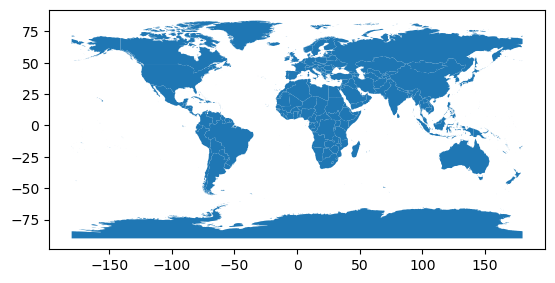

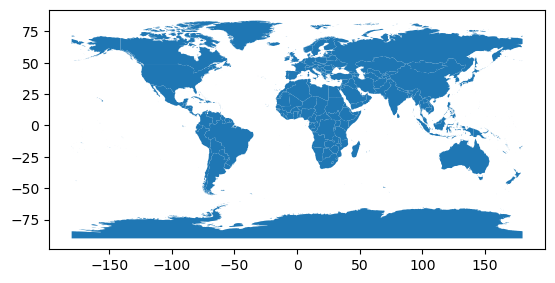

In [6]:
countries.plot()

In [7]:
print(countries.crs)

EPSG:4326


In [ ]:
# Verify that the CRS match

In [8]:
assert countries.crs == communities.crs

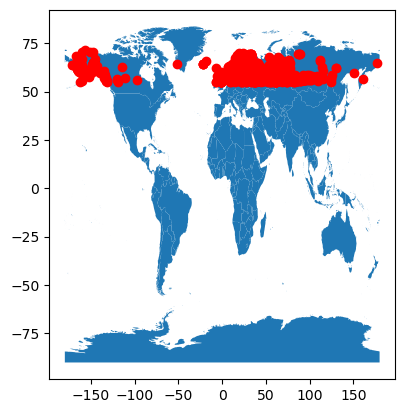

In [9]:
fig, ax = plt.subplots()

countries.plot(ax=ax)
communities.plot(ax=ax, color = 'red')
plt.show()

In [14]:
# Arctic communities by country

# Create a data frame with number of communities per country
n_comms = communities.groupby('country').size().reset_index(name='n_communities')

In [15]:
# Goal: merge the 'n_comms' and the 'countries' data frame

set(countries.columns).intersection(n_comms.columns)

set()

In [20]:
common_col = set(countries.columns).intersection(n_comms.columns)

# Check if there are any common col

if len(common_col) !=0:
    print(f"Common columns: {common_col}")
else:
    print("No common columns")

No common columns


In [21]:
# Make the previous code into a function called 'check_common_col' that takes in two dataframes as arguments

def check_common_col(df1, df2):
    common_col = set(df1.columns).intersection(df2.columns)

    if len(common_col) !=0:
        print(f"Common columns: {common_col}")
    else:
        print("No common columns")

In [22]:
check_common_col(countries, n_comms)

No common columns


In [23]:
## Merge data frames

# We can use the 'country names' to add teh country names

countries.head(3)

# use pandas merge() function
# output_df = pd.merge(left_df, right_df, how = type_of_join, on = columns to join on)
# output_df = df resulting from merge
# left_df = df we have on the left side
# right df= df on teh right rise
# how = type of join
# on = colunm to join on

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


In [25]:
check_common_col(n_comms, country_names)

Common columns: {'country'}


In [26]:
n_comms = pd.merge(n_comms,
                  country_names,
                  how='left',
                  on= 'country')

In [27]:
n_comms

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada
3,DK,72,Denmark
4,EE,14,Estonia
5,FI,98,Finland
6,FO,1,Faroe Islands
7,GB,96,United Kingdom
8,GL,1,Greenland
9,IS,5,Iceland


In [28]:
countries.head(3)

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


In [29]:
n_comms.head(3)

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada


In [36]:
arctic_countries = pd.merge(countries,
                  n_comms,
                  how='inner',
                  on= 'admin')

arctic_countries = countries.merge(n_comms, how='inner', on='admin')

In [37]:
arctic_countries.head(3)


,admin,type,geometry,country,n_communities
0,United States of America,Country,"MULTIPOLYGON (((-132.74687 56.52568, -132.7576...",US,115
1,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.62300, -2.74214 51...",GB,96
2,Sweden,Sovereign country,"MULTIPOLYGON (((19.07646 57.83594, 18.99375 57...",SE,133


In [ ]:
# When merging with a geoDataFrame, the GeoDataFRame needs to be the left data frame to keep the geomtry

## Review the results

In [38]:
print(f"Countries in n_comms: {len(n_comms)}")
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in n_comms: 16
Countries in arctic_countries: 15


In [39]:
# Countries in n_comms without a match in countries
n_comms[~n_comms['admin'].isin(countries['admin'])]

,country,n_communities,admin
0,AX,1,Aland Islands


In [40]:
countries[countries['admin'].str.contains('Aland')]

,admin,type,geometry
168,Aland,Country,"MULTIPOLYGON (((19.98955 60.35117, 20.02021 60..."


In [43]:
# Match the name used in teh countries data
n_comms['admin'] = n_comms['admin'].replace('Aland Islands', 'Aland')

arctic_countries = countries.merge(n_comms, how= 'inner', on= 'admin')
print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in arctic_countries: 16


<Axes: >

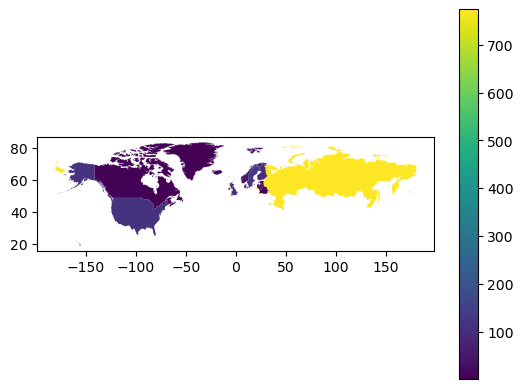

In [44]:
# Choropleth map
arctic_countries.plot(column='n_communities', 
                     legend=True)

In [45]:
## Reprojecting
# CRS optimized for the Arctic region
arctic_countries = arctic_countries.to_crs('epsg:3413')

In [46]:
## Reprojecting
# CRS optimized for the Arctic region
arctic_countries = arctic_countries.to_crs('epsg:3413')

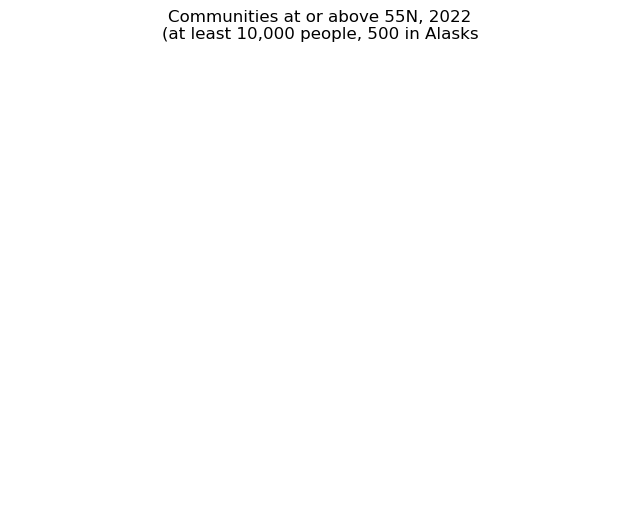

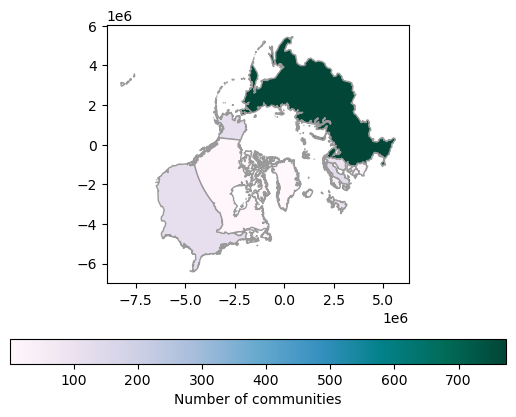

In [54]:
fig, ax = plt.subplots(figsize=(8,6))
ax.axis('off')
arctic_countries.plot(column='n_communities', 
                     legend=True,
                      edgecolor = "0.6",
                     cmap = 'PuBuGn',
                     legend_kwds={
                         "label": "Number of communities",
                         "orientation":"horizontal"
                     })
ax.set_title('Communities at or above 55N, 2022\n(at least 10,000 people, 500 in Alasks')
plt.show()